In [ ]:
import sys
print(sys.version)


In [ ]:
pip install pandas numpy scikit-learn matplotlib


In [ ]:
import os

os.chdir(r"D:\Transmission_Fault_ANN")
print(os.getcwd())
print(os.listdir())


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Transmission_Fault_Dataset.csv")

print("Dataset shape:", df.shape)
print("\nFault class distribution:")
print(df["Fault"].value_counts())

display(df.head())

In [ ]:
# Select electrical measurements as inputs
X = df[["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]]

# Select fault labels as outputs
y = df["Fault"]

print("Input shape:", X.shape)
print("Output shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nOutput classes:")
print(sorted(y.unique()))


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Convert fault labels into numeric classes
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Standardize features using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Number of classes:", len(label_encoder.classes_))
print("Classes:", label_encoder.classes_)


In [ ]:

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Create the ANN model
ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42,
    early_stopping=True
)

# Train the model
ann.fit(X_train_scaled, y_train)

# Predict fault classes for test data
y_pred = ann.predict(X_test_scaled)

# Calculate baseline accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Baseline ANN Accuracy: {accuracy * 100:.2f}%")
print("Training iterations:", ann.n_iter_)



In [ ]:

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Detailed performance for each fault class
print(classification_report(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("ANN - Fault Classification Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
from sklearn.metrics import confusion_matrix

cm_df = pd.DataFrame(
    confusion_matrix(
        y_test,
        y_pred,
        labels=label_encoder.transform(label_encoder.classes_)
    ),
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

print("Rows = Actual faults | Columns = Predicted faults")
display(cm_df)


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

folder = r"D:\Transmission_Fault_ANN"

ll = pd.read_csv(folder + r"\LL.csv")
lll = pd.read_csv(folder + r"\LLL.csv")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for col in ["Ia", "Ib", "Ic"]:
    axes[0].plot(ll["Time"], ll[col], label=col)

axes[0].axvspan(0.1, 0.15, alpha=0.15)
axes[0].set_title("LL Fault - Three-Phase Currents")
axes[0].set_ylabel("Current (A)")
axes[0].legend()
axes[0].grid(True)

for col in ["Ia", "Ib", "Ic"]:
    axes[1].plot(lll["Time"], lll[col], label=col)

axes[1].axvspan(0.1, 0.15, alpha=0.15)
axes[1].set_title("LLL Fault - Three-Phase Currents")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Current (A)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np

folder = r"D:\Transmission_Fault_ANN"

ll = pd.read_csv(folder + r"\LL.csv")
lll = pd.read_csv(folder + r"\LLL.csv")

for col in ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]:
    same = np.allclose(ll[col].to_numpy(), lll[col].to_numpy())
    print(f"{col}: {'IDENTICAL' if same else 'DIFFERENT'}")

In [ ]:
import pandas as pd
import numpy as np

folder = r"D:\Transmission_Fault_ANN"

ll = pd.read_csv(folder + r"\LL.csv")
lll = pd.read_csv(folder + r"\LLL.csv")

# Check the time range first
print("LL time range:", ll["Time"].min(), ll["Time"].max())
print("LLL time range:", lll["Time"].min(), lll["Time"].max())

# Compare currents during the fault (0.1 to 0.15 seconds)
ll_fault = ll[(ll["Time"] >= 0.1) & (ll["Time"] <= 0.15)]
lll_fault = lll[(lll["Time"] >= 0.1) & (lll["Time"] <= 0.15)]

for col in ["Ia", "Ib", "Ic"]:
    print(f"\n{col}")
    print("LL mean absolute current:", ll_fault[col].abs().mean())
    print("LLL mean absolute current:", lll_fault[col].abs().mean())

In [ ]:
import pandas as pd

folder = r"D:\Transmission_Fault_ANN"

for filename in ["LL.csv", "LLL.csv"]:
    df = pd.read_csv(folder + "\\" + filename)

    print(f"\n{filename}")
    print("First 10 time values:")
    print(df["Time"].head(10).to_list())
    print("Last 5 time values:")
    print(df["Time"].tail(5).to_list())
    print("Number of rows:", len(df))

In [ ]:
for col in ["Ia", "Ib", "Ic"]:
    print(f"\n{col}")
    print("LL mean absolute current:", ll[col].abs().mean())
    print("LLL mean absolute current:", lll[col].abs().mean())

In [ ]:
import numpy as np

for col in ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]:
    a = ll[col].to_numpy()
    b = lll[col].to_numpy()

    print(f"\n{col}")
    print("Maximum absolute difference:", np.max(np.abs(a - b)))
    print("Correlation:", np.corrcoef(a, b)[0, 1])

In [ ]:
import pandas as pd
import os

folder = r"D:\Transmission_Fault_ANN"

for filename in ["LL_full.csv", "LLL_full.csv"]:
    path = os.path.join(folder, filename)
    df = pd.read_csv(path)

    print(
        filename,
        "| Samples:", len(df),
        "| Start:", df["Time"].min(),
        "| End:", df["Time"].max()
    )

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

folder = r"D:\Transmission_Fault_ANN"

ll = pd.read_csv(os.path.join(folder, "LL_full.csv"))
lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for col in ["Ia", "Ib", "Ic"]:
    axes[0].plot(ll["Time"], ll[col], label=col)
    axes[1].plot(lll["Time"], lll[col], label=col)

for ax in axes:
    ax.axvspan(0.1, 0.15, alpha=0.2)
    ax.legend()
    ax.grid(True)

axes[0].set_title("LL Fault Currents")
axes[1].set_title("LLL Fault Currents")
axes[1].set_xlabel("Time (s)")
axes[0].set_ylabel("Current (A)")
axes[1].set_ylabel("Current (A)")

plt.tight_layout()
plt.show()

In [ ]:

import os
import pandas as pd

folder = r"D:\Transmission_Fault_ANN"

files = {
    "Normal": "Normal_full.csv",
    "LG": "LG_full.csv",
    "LL": "LL_full.csv",
    "LLG": "LLG_full.csv",
    "LLL": "LLL_full.csv",
    "LLLG": "LLLG_full.csv"
}

frames = []

for fault_name, filename in files.items():
    path = os.path.join(folder, filename)

    data = pd.read_csv(path)
    data["Fault"] = fault_name
    frames.append(data)

    print(
        f"{filename}: {len(data)} samples, "
        f"time = {data['Time'].min()} to {data['Time'].max()} s"
    )

# Combine all six datasets
full_df = pd.concat(frames, ignore_index=True)

# Save the combined dataset
output_path = os.path.join(
    folder, "Transmission_Fault_Dataset_full.csv"
)
full_df.to_csv(output_path, index=False)

print("\nCombined dataset shape:", full_df.shape)
print("\nSamples per fault:")
print(full_df["Fault"].value_counts())
print("\nSaved to:", output_path)


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

folder = r"D:\Transmission_Fault_ANN"
df = pd.read_csv(
    os.path.join(folder, "Transmission_Fault_Dataset_full.csv")
)

# 1. Check data quality
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nSamples per class:")
print(df["Fault"].value_counts())

# 2. Plot phase-A current for each fault class
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
axes = axes.flatten()

for ax, fault in zip(
    axes, ["Normal", "LG", "LL", "LLG", "LLL", "LLLG"]
):
    subset = df[df["Fault"] == fault]

    ax.plot(subset["Time"], subset["Ia"], linewidth=0.8)
    ax.axvspan(0.1, 0.15, alpha=0.2)
    ax.set_title(f"{fault} - Phase A Current")
    ax.set_ylabel("Current (A)")
    ax.grid(True)

axes[-1].set_xlabel("Time (s)")
axes[-2].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

llg = pd.read_csv(os.path.join(folder, "LLG_full.csv"))
lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))

# Compare only during the fault interval
start, end = 0.1, 0.15
llg_fault = llg[(llg["Time"] >= start) & (llg["Time"] <= end)]
lll_fault = lll[(lll["Time"] >= start) & (lll["Time"] <= end)]

for col in ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]:
    a = llg_fault[col].to_numpy()
    b = lll_fault[col].to_numpy()

    print(
        f"{col}: "
        f"LLG RMS = {np.sqrt(np.mean(a**2)):.4f}, "
        f"LLL RMS = {np.sqrt(np.mean(b**2)):.4f}, "
        f"Mean absolute difference = {np.mean(np.abs(a-b)):.4f}"
    )


In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_full.csv"))

# Compare only during the fault interval
a = lll[(lll["Time"] >= 0.1) & (lll["Time"] <= 0.15)]
b = lllg[(lllg["Time"] >= 0.1) & (lllg["Time"] <= 0.15)]

for col in ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]:
    x = a[col].to_numpy()
    y = b[col].to_numpy()

    print(
        f"{col}: LLL RMS={np.sqrt(np.mean(x**2)):.3f}, "
        f"LLLG RMS={np.sqrt(np.mean(y**2)):.3f}, "
        f"Mean difference={np.mean(np.abs(x-y)):.3f}"
    )



In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_full.csv"))

signals = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]

print("Same time values:", np.array_equal(lll["Time"], lllg["Time"]))

for col in signals:
    difference = np.abs(lll[col] - lllg[col])
    print(
        f"{col}: maximum difference = {difference.max():.10f}"
    )

print("\nLLL first rows:")
print(lll.head(3))

print("\nLLLG first rows:")
print(lllg.head(3))


In [ ]:

import numpy as np
import pandas as pd
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_full.csv"))

signals = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]

periods = {
    "Before fault": (lll["Time"] < 0.1),
    "During fault": ((lll["Time"] >= 0.1) & (lll["Time"] <= 0.15)),
    "After fault": (lll["Time"] > 0.15)
}

for period, mask in periods.items():
    print(f"\n--- {period} ---")

    for col in signals:
        x = lll.loc[mask, col].to_numpy()
        y = lllg.loc[mask, col].to_numpy()
        difference = np.abs(x - y)

        print(
            f"{col}: max difference={difference.max():.8e}, "
            f"mean difference={difference.mean():.8e}"
        )


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_full.csv"))

fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)

for row, phase in enumerate(["Va", "Vb", "Vc"]):
    axes[row, 0].plot(lll["Time"], lll[phase], label="LLL")
    axes[row, 0].plot(lllg["Time"], lllg[phase], "--", label="LLLG")
    axes[row, 0].set_title(phase)
    axes[row, 0].set_xlim(0.095, 0.155)
    axes[row, 0].legend()
    axes[row, 0].grid(True)

for row, phase in enumerate(["Ia", "Ib", "Ic"]):
    axes[row, 1].plot(lll["Time"], lll[phase], label="LLL")
    axes[row, 1].plot(lllg["Time"], lllg[phase], "--", label="LLLG")
    axes[row, 1].set_title(phase)
    axes[row, 1].set_xlim(0.095, 0.155)
    axes[row, 1].legend()
    axes[row, 1].grid(True)

plt.tight_layout()
plt.show()

print("\nMaximum signal differences during the fault:")
mask = (lll["Time"] >= 0.1) & (lll["Time"] <= 0.15)

for col in ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]:
    diff = np.abs(
        lll.loc[mask, col].to_numpy()
        - lllg.loc[mask, col].to_numpy()
    )
    print(f"{col}: {diff.max():.8e}")



In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

# Load the reference LLL dataset and updated LLLG dataset
lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_full.csv"))

# Select only the fault interval: 0.1 to 0.15 seconds
mask = (lll["Time"] >= 0.1) & (lll["Time"] <= 0.15)

signals = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]

print("Maximum signal differences during the fault:\n")

for col in signals:
    x = lll.loc[mask, col].to_numpy()
    y = lllg.loc[mask, col].to_numpy()

    max_diff = np.max(np.abs(x - y))
    mean_diff = np.mean(np.abs(x - y))

    print(
        f"{col}: maximum difference = {max_diff:.8e}, "
        f"mean difference = {mean_diff:.8e}"
    )


In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_full.csv"))

# Compare during the fault interval
mask = (lll["Time"] >= 0.1) & (lll["Time"] <= 0.15)

print("LLL vs LLLG: fault-interval comparison\n")

for col in ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]:
    x = lll.loc[mask, col].to_numpy()
    y = lllg.loc[mask, col].to_numpy()

    print(
        f"{col}: LLL RMS={np.sqrt(np.mean(x**2)):.4f}, "
        f"LLLG RMS={np.sqrt(np.mean(y**2)):.4f}, "
        f"max difference={np.max(np.abs(x-y)):.8e}"
    )


In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"
data = pd.read_csv(os.path.join(folder, "LLLG_full.csv"))

for name, mask in {
    "Before fault": data["Time"] < 0.1,
    "During fault": (data["Time"] >= 0.1) & (data["Time"] <= 0.15),
    "After fault": data["Time"] > 0.15
}.items():
    print(f"\n{name}")
    for col in ["Ia", "Ib", "Ic"]:
        x = data.loc[mask, col].to_numpy()
        print(f"{col} RMS: {np.sqrt(np.mean(x**2)):.4f} A")


In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_full.csv"))

periods = {
    "Before fault": lll["Time"] < 0.1,
    "During fault": (lll["Time"] >= 0.1) & (lll["Time"] <= 0.15),
    "After fault": lll["Time"] > 0.15
}

for period, mask in periods.items():
    print(f"\n{period}")

    for col in ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]:
        x = lll.loc[mask, col].to_numpy()
        y = lllg.loc[mask, col].to_numpy()

        print(
            f"{col}: "
            f"LLL RMS={np.sqrt(np.mean(x**2)):.3f}, "
            f"LLLG RMS={np.sqrt(np.mean(y**2)):.3f}"
        )


In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_test.csv"))

# Compare measurements only during the fault (0.1–0.15 s)
mask1 = (lll["Time"] >= 0.1) & (lll["Time"] <= 0.15)
mask2 = (lllg["Time"] >= 0.1) & (lllg["Time"] <= 0.15)

columns = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]

print("RMS values during fault:\n")

for col in columns:
    x = lll.loc[mask1, col].to_numpy()
    y = lllg.loc[mask2, col].to_numpy()

    print(
        f"{col}: LLL = {np.sqrt(np.mean(x**2)):.3f}, "
        f"LLLG = {np.sqrt(np.mean(y**2)):.3f}, "
        f"max difference = {np.max(np.abs(x-y)):.6f}"
    )


In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_test.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_test.csv"))

columns = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]

# Compare the fault interval
mask1 = (lll["Time"] >= 0.1) & (lll["Time"] <= 0.15)
mask2 = (lllg["Time"] >= 0.1) & (lllg["Time"] <= 0.15)

print("Updated comparison during fault:\n")

for col in columns:
    x = lll.loc[mask1, col].to_numpy()
    y = lllg.loc[mask2, col].to_numpy()

    rms_lll = np.sqrt(np.mean(x**2))
    rms_lllg = np.sqrt(np.mean(y**2))

    print(
        f"{col}: LLL = {rms_lll:.3f}, "
        f"LLLG = {rms_lllg:.3f}, "
        f"Difference = {abs(rms_lll-rms_lllg):.3f}"
    )


In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_test.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_test.csv"))

print("Same shape:", lll.shape == lllg.shape)
print("Same time values:",
      np.allclose(lll["Time"], lllg["Time"]))

for col in ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]:
    difference = np.max(
        np.abs(lll[col].to_numpy() - lllg[col].to_numpy())
    )
    print(f"{col}: maximum difference = {difference:.10f}")


In [ ]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

lll = pd.read_csv(os.path.join(folder, "LLL_test.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_test.csv"))

print("Maximum difference during each interval:\n")

for period, mask in {
    "Before fault": lll["Time"] < 0.1,
    "During fault": (lll["Time"] >= 0.1) & (lll["Time"] <= 0.15),
    "After fault": lll["Time"] > 0.15
}.items():
    print(f"\n{period}")

    for col in ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]:
        x = lll.loc[mask, col].to_numpy()
        y = lllg.loc[mask, col].to_numpy()

        print(f"{col}: {np.max(np.abs(x-y)):.6f}")


In [1]:

import pandas as pd
import os

folder = r"D:\Transmission_Fault_ANN"

# Original datasets for five classes
files = {
    "Normal": "Normal_full.csv",
    "LG": "LG_full.csv",
    "LL": "LL_full.csv",
    "LLG": "LLG_full.csv",
    "LLL": "LLL_full.csv",
    "LLLG": "LLLG_test.csv"
}

datasets = []

for fault, filename in files.items():
    path = os.path.join(folder, filename)

    data = pd.read_csv(path)

    # Assign the correct fault label
    data["Fault"] = fault

    datasets.append(data)

    print(f"{filename}: {len(data)} rows loaded")

# Combine all six classes
combined_df = pd.concat(datasets, ignore_index=True)

# Save as a new file; preserve your previous combined dataset
output_path = os.path.join(
    folder,
    "Transmission_Fault_Dataset_updated.csv"
)

combined_df.to_csv(output_path, index=False)

print("\nUpdated dataset created!")
print("Shape:", combined_df.shape)
print("\nSamples per fault class:")
print(combined_df["Fault"].value_counts())

print("\nFirst five rows:")
display(combined_df.head())


Normal_full.csv: 4001 rows loaded
LG_full.csv: 4001 rows loaded
LL_full.csv: 4001 rows loaded
LLG_full.csv: 4001 rows loaded
LLL_full.csv: 4001 rows loaded
LLLG_test.csv: 4001 rows loaded

Updated dataset created!
Shape: (24006, 8)

Samples per fault class:
Fault
Normal    4001
LG        4001
LL        4001
LLG       4001
LLL       4001
LLLG      4001
Name: count, dtype: int64

First five rows:


,Time,Va,Vb,Vc,Ia,Ib,Ic,Fault
0,0.00000,-10.683037,-12854.113821,12864.796858,116.494768,-54.180238,-62.314530,Normal
1,0.00005,254.964490,-12985.032591,12730.068101,116.352998,-51.855661,-64.497337,Normal
2,0.00010,520.528872,-13111.767478,12591.238607,116.155808,-49.506574,-66.649233,Normal
3,0.00015,785.923566,-13234.277203,12448.353637,115.903286,-47.134014,-68.769272,Normal
4,0.00020,1051.062184,-13352.521926,12301.459742,115.595543,-44.739024,-70.856519,Normal


In [2]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

file_path = os.path.join(
    folder,
    "Transmission_Fault_Dataset_updated.csv"
)

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nInfinite values in measurement columns:")
measurement_cols = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]

print(
    np.isinf(df[measurement_cols]).sum()
)

print("\nFault labels:")
print(sorted(df["Fault"].unique()))


Dataset shape: (24006, 8)

Missing values:
Time     0
Va       0
Vb       0
Vc       0
Ia       0
Ib       0
Ic       0
Fault    0
dtype: int64

Duplicate rows: 0

Infinite values in measurement columns:
Va    0
Vb    0
Vc    0
Ia    0
Ib    0
Ic    0
dtype: int64

Fault labels:
['LG', 'LL', 'LLG', 'LLL', 'LLLG', 'Normal']


In [4]:

import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

# Six electrical input features
feature_cols = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]

X = df[feature_cols].copy()
y = df["Fault"].copy()

# Convert fault names into numerical labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Input shape:", X.shape)
print("Output shape:", y_encoded.shape)

print("\nFault-to-number mapping:")
for number, fault in enumerate(label_encoder.classes_):
    print(f"{fault} = {number}")

print("\nFirst five input samples:")
display(X.head())

print("\nFirst five encoded labels:")
print(y_encoded[:5])


Input shape: (24006, 6)
Output shape: (24006,)

Fault-to-number mapping:
LG = 0
LL = 1
LLG = 2
LLL = 3
LLLG = 4
Normal = 5

First five input samples:


,Va,Vb,Vc,Ia,Ib,Ic
0,-10.683037,-12854.113821,12864.796858,116.494768,-54.180238,-62.314530
1,254.964490,-12985.032591,12730.068101,116.352998,-51.855661,-64.497337
2,520.528872,-13111.767478,12591.238607,116.155808,-49.506574,-66.649233
3,785.923566,-13234.277203,12448.353637,115.903286,-47.134014,-68.769272
4,1051.062184,-13352.521926,12301.459742,115.595543,-44.739024,-70.856519



First five encoded labels:
[5 5 5 5 5]


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Scale using ONLY the training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training input shape:", X_train_scaled.shape)
print("Testing input shape:", X_test_scaled.shape)

print("\nTraining labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

print("\nFirst five scaled training samples:")
print(X_train_scaled[:5])



Training input shape: (19204, 6)
Testing input shape: (4802, 6)

Training labels shape: (19204,)
Testing labels shape: (4802,)

First five scaled training samples:
[[-7.62795787e-01  1.29360574e+00  2.49897085e-01 -1.95274826e+00
   4.13568536e-01  1.57479185e+00]
 [-1.45096798e-01  1.37219317e+00 -1.14876238e+00 -1.30618719e+00
   1.57143349e+00 -2.80037930e-01]
 [-1.08090353e+00  1.10911673e+00 -6.34090347e-02 -2.49461342e-01
   1.75365031e-01  6.34222673e-02]
 [-2.07681911e+00  9.07274859e-01  1.02084494e+00 -5.02134952e-01
  -2.29838869e-01  7.38532335e-01]
 [ 1.41259973e-02 -6.26725570e-04 -1.29163469e-01  2.28256595e-01
  -1.87409427e+00  1.92279374e+00]]


In [6]:

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Create the ANN
ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
    early_stopping=True
)

# Train the ANN
print("Training ANN...")

ann.fit(X_train_scaled, y_train)

print("Training completed!")

# Predict fault classes for the test data
y_pred = ann.predict(X_test_scaled)

# Calculate baseline accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"\nBaseline test accuracy: {accuracy * 100:.2f}%")
print("Number of training iterations:", ann.n_iter_)


Training ANN...
Training completed!

Baseline test accuracy: 53.83%
Number of training iterations: 99


In [7]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

print("CONFUSION MATRIX")
print("Rows = Actual class | Columns = Predicted class")
display(cm_df)

# Performance for each fault type
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))



CONFUSION MATRIX
Rows = Actual class | Columns = Predicted class


,LG,LL,LLG,LLL,LLLG,Normal
LG,340,47,59,23,0,331
LL,0,312,1,84,1,402
LLG,55,35,310,26,2,372
LLL,1,98,1,212,84,405
LLLG,0,0,0,63,738,0
Normal,0,84,1,42,0,673



CLASSIFICATION REPORT
              precision    recall  f1-score   support

          LG       0.86      0.42      0.57       800
          LL       0.54      0.39      0.45       800
         LLG       0.83      0.39      0.53       800
         LLL       0.47      0.26      0.34       801
        LLLG       0.89      0.92      0.91       801
      Normal       0.31      0.84      0.45       800

    accuracy                           0.54      4802
   macro avg       0.65      0.54      0.54      4802
weighted avg       0.65      0.54      0.54      4802



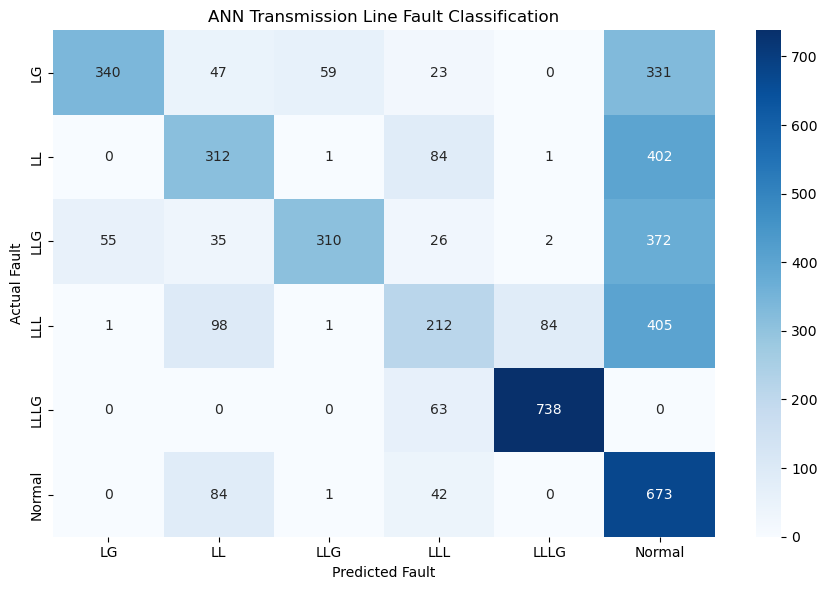

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Fault")
plt.ylabel("Actual Fault")
plt.title("ANN Transmission Line Fault Classification")
plt.tight_layout()
plt.show()


In [9]:

import pandas as pd
import os

folder = r"D:\Transmission_Fault_ANN"

# Load the existing datasets
normal = pd.read_csv(os.path.join(folder, "Normal_full.csv"))
lg = pd.read_csv(os.path.join(folder, "LG_full.csv"))
ll = pd.read_csv(os.path.join(folder, "LL_full.csv"))
lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_test.csv"))

# Load the NEW LLG dataset
llg = pd.read_csv(os.path.join(folder, "LLG_BC.csv"))

# Assign labels
normal["Fault"] = "Normal"
lg["Fault"] = "LG"
ll["Fault"] = "LL"
llg["Fault"] = "LLG"
lll["Fault"] = "LLL"
lllg["Fault"] = "LLLG"

# Combine all six classes
df = pd.concat(
    [normal, lg, ll, llg, lll, lllg],
    ignore_index=True
)

# Save as a new file; preserve previous datasets
output_path = os.path.join(
    folder, "Transmission_Fault_Dataset_v2.csv"
)
df.to_csv(output_path, index=False)

print("Updated dataset shape:", df.shape)
print("\nSamples per class:")
print(df["Fault"].value_counts())
print("\nSaved to:", output_path)


Updated dataset shape: (24006, 8)

Samples per class:
Fault
Normal    4001
LG        4001
LL        4001
LLG       4001
LLL       4001
LLLG      4001
Name: count, dtype: int64

Saved to: D:\Transmission_Fault_ANN\Transmission_Fault_Dataset_v2.csv


In [10]:

import pandas as pd
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# 1. Load the UPDATED dataset
folder = r"D:\Transmission_Fault_ANN"
file_path = os.path.join(folder, "Transmission_Fault_Dataset_v2.csv")

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nSamples per class:")
print(df["Fault"].value_counts())

# 2. Select input features and target
feature_cols = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]
X = df[feature_cols]
y = df["Fault"]

# 3. Encode fault labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nClass mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(label, "=", i)

# 4. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# 5. Standardize input features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Create and train the ANN
fault_ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
    early_stopping=True
)

print("\nTraining fault_ann...")
fault_ann.fit(X_train_scaled, y_train)
print("Training completed!")

# 7. Evaluate the model
y_pred = fault_ann.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f"\nUpdated ANN test accuracy: {accuracy * 100:.2f}%")
print("Training iterations:", fault_ann.n_iter_)


Dataset shape: (24006, 8)

Samples per class:
Fault
Normal    4001
LG        4001
LL        4001
LLG       4001
LLL       4001
LLLG      4001
Name: count, dtype: int64

Class mapping:
LG = 0
LL = 1
LLG = 2
LLL = 3
LLLG = 4
Normal = 5

Training fault_ann...
Training completed!

Updated ANN test accuracy: 49.52%
Training iterations: 55


In [11]:

from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

# Predict using the updated ANN
y_pred = fault_ann.predict(X_test_scaled)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_))
)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

print("UPDATED ANN - CONFUSION MATRIX")
print("Rows = Actual | Columns = Predicted")
display(cm_df)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


UPDATED ANN - CONFUSION MATRIX
Rows = Actual | Columns = Predicted


,LG,LL,LLG,LLL,LLLG,Normal
LG,385,47,0,71,0,297
LL,35,220,0,196,10,339
LLG,0,0,678,0,122,0
LLL,40,72,1,264,119,305
LLLG,0,7,457,54,283,0
Normal,42,87,0,123,0,548



CLASSIFICATION REPORT
              precision    recall  f1-score   support

          LG       0.77      0.48      0.59       800
          LL       0.51      0.28      0.36       800
         LLG       0.60      0.85      0.70       800
         LLL       0.37      0.33      0.35       801
        LLLG       0.53      0.35      0.42       801
      Normal       0.37      0.69      0.48       800

    accuracy                           0.50      4802
   macro avg       0.52      0.50      0.48      4802
weighted avg       0.52      0.50      0.48      4802



In [12]:

import pandas as pd
import os
import numpy as np

folder = r"D:\Transmission_Fault_ANN"

# Load the new standalone LLG dataset
new_llg = pd.read_csv(os.path.join(folder, "LLG_BC.csv"))

# Extract LLG rows from the combined dataset
combined_llg = df[df["Fault"] == "LLG"].copy()

features = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]

print("New LLG shape:", new_llg.shape)
print("Combined LLG shape:", combined_llg.shape)

# Compare measurement values, ignoring the Fault label
if len(new_llg) == len(combined_llg):
    same_values = np.allclose(
        new_llg[features].to_numpy(),
        combined_llg[features].to_numpy(),
        equal_nan=True
    )
    print("Combined LLG matches new LLG measurements:", same_values)
else:
    print("Row counts differ; direct comparison is not possible.")


New LLG shape: (4001, 7)
Combined LLG shape: (4001, 8)
Combined LLG matches new LLG measurements: True


In [13]:

import pandas as pd
import os

folder = r"D:\Transmission_Fault_ANN"

# Load existing datasets
normal = pd.read_csv(os.path.join(folder, "Normal_full.csv"))
lg = pd.read_csv(os.path.join(folder, "LG_full.csv"))

# Use the NEW LL dataset
ll = pd.read_csv(os.path.join(folder, "LL_AC.csv"))

# Use the NEW LLG dataset
llg = pd.read_csv(os.path.join(folder, "LLG_BC.csv"))

lll = pd.read_csv(os.path.join(folder, "LLL_full.csv"))
lllg = pd.read_csv(os.path.join(folder, "LLLG_test.csv"))

# Assign labels
normal["Fault"] = "Normal"
lg["Fault"] = "LG"
ll["Fault"] = "LL"
llg["Fault"] = "LLG"
lll["Fault"] = "LLL"
lllg["Fault"] = "LLLG"

# Combine datasets
df_v3 = pd.concat(
    [normal, lg, ll, llg, lll, lllg],
    ignore_index=True
)

# Save as a new version
output_path = os.path.join(
    folder, "Transmission_Fault_Dataset_v3.csv"
)
df_v3.to_csv(output_path, index=False)

print("Dataset shape:", df_v3.shape)
print("\nSamples per class:")
print(df_v3["Fault"].value_counts())
print("\nSaved to:", output_path)


Dataset shape: (24006, 8)

Samples per class:
Fault
Normal    4001
LG        4001
LL        4001
LLG       4001
LLL       4001
LLLG      4001
Name: count, dtype: int64

Saved to: D:\Transmission_Fault_ANN\Transmission_Fault_Dataset_v3.csv


In [14]:

import pandas as pd
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# 1. Load updated dataset
folder = r"D:\Transmission_Fault_ANN"
file_path = os.path.join(folder, "Transmission_Fault_Dataset_v3.csv")

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nClass counts:")
print(df["Fault"].value_counts())

# 2. Prepare inputs and target
feature_cols = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]
X = df[feature_cols]
y = df["Fault"]

# 3. Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# 5. Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Create and train ANN
fault_ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
    early_stopping=True
)

print("\nTraining fault_ann...")
fault_ann.fit(X_train_scaled, y_train)

print("Training completed!")

# 7. Evaluate
y_pred = fault_ann.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f"\nDataset v3 test accuracy: {accuracy * 100:.2f}%")
print("Training iterations:", fault_ann.n_iter_)


Dataset shape: (24006, 8)

Class counts:
Fault
Normal    4001
LG        4001
LL        4001
LLG       4001
LLL       4001
LLLG      4001
Name: count, dtype: int64

Training fault_ann...
Training completed!

Dataset v3 test accuracy: 46.23%
Training iterations: 30


In [15]:

import pandas as pd
import numpy as np
import os

folder = r"D:\Transmission_Fault_ANN"

old_ll = pd.read_csv(os.path.join(folder, "LL_full.csv"))
new_ll = pd.read_csv(os.path.join(folder, "LL_AC.csv"))

features = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]

print("Old LL shape:", old_ll.shape)
print("New LL shape:", new_ll.shape)

print("\nOld LL measurement statistics:")
display(old_ll[features].describe().round(3))

print("\nNew LL measurement statistics:")
display(new_ll[features].describe().round(3))


Old LL shape: (4001, 7)
New LL shape: (4001, 7)

Old LL measurement statistics:


,Va,Vb,Vc,Ia,Ib,Ic
count,4001.000,4001.000,4001.000,4001.000,4001.000,4001.000
mean,-113.570,110.348,3.220,52.698,-52.682,-0.016
std,7260.210,7204.989,7971.883,197.932,215.965,197.226
min,-18655.788,-17252.046,-14520.596,-364.808,-523.041,-375.671
25%,-5331.910,-5027.489,-6367.299,-106.951,-211.971,-159.064
50%,18.139,168.125,2.742,77.340,-51.856,0.393
75%,5147.620,5337.854,6581.470,202.401,123.817,150.282
max,18005.108,18463.620,14835.629,420.231,371.665,370.404



New LL measurement statistics:


,Va,Vb,Vc,Ia,Ib,Ic
count,4001.000,4001.000,4001.000,4001.000,4001.000,4001.000
mean,-78.643,-1.926,80.571,36.499,-0.002,-36.498
std,5703.640,6455.025,5776.673,100.967,5.705,103.446
min,-9131.975,-9127.702,-9126.950,-132.247,-8.071,-391.775
25%,-4537.698,-6480.289,-4492.462,-6.047,-5.729,-7.719
50%,-266.871,-38.307,-52.209,1.763,-0.041,-1.920
75%,4492.000,6426.889,4562.468,7.841,5.673,6.279
max,9183.818,9127.705,13086.063,383.913,8.071,140.012


In [16]:

import numpy as np
import pandas as pd
import os

folder = r"D:\Transmission_Fault_ANN"

old_ll = pd.read_csv(os.path.join(folder, "LL_full.csv"))
new_ll = pd.read_csv(os.path.join(folder, "LL_AC.csv"))

def check_fault_interval(data, name):
    # Use the Time column if it exists
    if "Time" not in data.columns:
        print(f"{name}: Time column not found.")
        return

    fault_data = data[
        (data["Time"] >= 0.1) &
        (data["Time"] <= 0.15)
    ]

    print(f"\n{name} — fault interval")
    print("Number of samples:", len(fault_data))

    for phase in ["Ia", "Ib", "Ic"]:
        rms = np.sqrt(np.mean(fault_data[phase] ** 2))
        print(f"{phase} RMS: {rms:.3f} A")

check_fault_interval(old_ll, "OLD LL")
check_fault_interval(new_ll, "NEW LL")




OLD LL — fault interval
Number of samples: 1001
Ia RMS: 232.147 A
Ib RMS: 303.266 A
Ic RMS: 192.262 A

NEW LL — fault interval
Number of samples: 1001
Ia RMS: 196.378 A
Ib RMS: 5.708 A
Ic RMS: 200.629 A


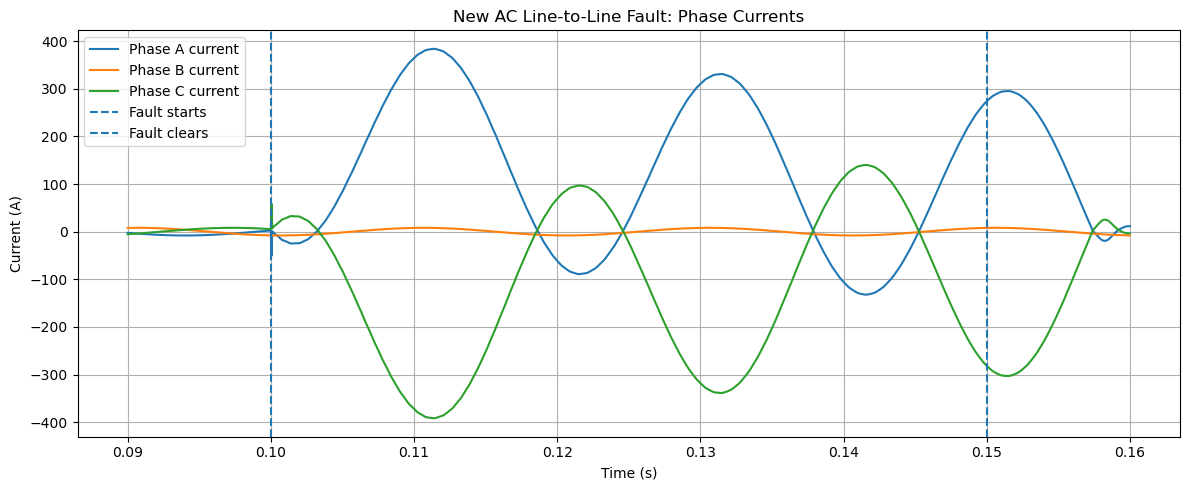

In [17]:

import pandas as pd
import matplotlib.pyplot as plt
import os

folder = r"D:\Transmission_Fault_ANN"
new_ll = pd.read_csv(os.path.join(folder, "LL_AC.csv"))

# Select the fault interval
fault_data = new_ll[
    (new_ll["Time"] >= 0.09) &
    (new_ll["Time"] <= 0.16)
]

plt.figure(figsize=(12, 5))

plt.plot(fault_data["Time"], fault_data["Ia"], label="Phase A current")
plt.plot(fault_data["Time"], fault_data["Ib"], label="Phase B current")
plt.plot(fault_data["Time"], fault_data["Ic"], label="Phase C current")

plt.axvline(0.1, linestyle="--", label="Fault starts")
plt.axvline(0.15, linestyle="--", label="Fault clears")

plt.xlabel("Time (s)")
plt.ylabel("Current (A)")
plt.title("New AC Line-to-Line Fault: Phase Currents")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [18]:

import pandas as pd
import os

folder = r"D:\Transmission_Fault_ANN"
file_path = os.path.join(folder, "Transmission_Fault_Dataset_full.csv")

df = pd.read_csv(file_path)

print("Original dataset restored!")
print("Dataset shape:", df.shape)
print("\nSamples per class:")
print(df["Fault"].value_counts())


Original dataset restored!
Dataset shape: (24006, 8)

Samples per class:
Fault
Normal    4001
LG        4001
LL        4001
LLG       4001
LLL       4001
LLLG      4001
Name: count, dtype: int64


In [20]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

feature_cols = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]
X = df[feature_cols]
y = df["Fault"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

fault_ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
    early_stopping=True
)

fault_ann.fit(X_train_scaled, y_train)

y_pred = fault_ann.predict(X_test_scaled)

print(f"Original ANN accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("Training iterations:", fault_ann.n_iter_)


Original ANN accuracy: 37.15%
Training iterations: 34


In [21]:

import pandas as pd
import os

folder = r"D:\Transmission_Fault_ANN"

files = [
    "Transmission_Fault_Dataset_full.csv",
    "Transmission_Fault_Dataset_updated.csv",
    "Transmission_Fault_Dataset_v2.csv",
    "Transmission_Fault_Dataset_v3.csv"
]

for filename in files:
    path = os.path.join(folder, filename)

    if os.path.exists(path):
        data = pd.read_csv(path)
        print(f"\n{filename}")
        print("Shape:", data.shape)
        print("Class counts:")
        print(data["Fault"].value_counts().sort_index().to_dict())



Transmission_Fault_Dataset_full.csv
Shape: (24006, 8)
Class counts:
{'LG': 4001, 'LL': 4001, 'LLG': 4001, 'LLL': 4001, 'LLLG': 4001, 'Normal': 4001}

Transmission_Fault_Dataset_updated.csv
Shape: (24006, 8)
Class counts:
{'LG': 4001, 'LL': 4001, 'LLG': 4001, 'LLL': 4001, 'LLLG': 4001, 'Normal': 4001}

Transmission_Fault_Dataset_v2.csv
Shape: (24006, 8)
Class counts:
{'LG': 4001, 'LL': 4001, 'LLG': 4001, 'LLL': 4001, 'LLLG': 4001, 'Normal': 4001}

Transmission_Fault_Dataset_v3.csv
Shape: (24006, 8)
Class counts:
{'LG': 4001, 'LL': 4001, 'LLG': 4001, 'LLL': 4001, 'LLLG': 4001, 'Normal': 4001}


In [22]:

import pandas as pd
import os
import hashlib

folder = r"D:\Transmission_Fault_ANN"

files = [
    "Transmission_Fault_Dataset_full.csv",
    "Transmission_Fault_Dataset_updated.csv",
    "Transmission_Fault_Dataset_v2.csv",
    "Transmission_Fault_Dataset_v3.csv"
]

for filename in files:
    path = os.path.join(folder, filename)

    with open(path, "rb") as f:
        file_hash = hashlib.md5(f.read()).hexdigest()

    print(filename, "->", file_hash)


Transmission_Fault_Dataset_full.csv -> 8c6256c038689c8f46e5489693e80e6b
Transmission_Fault_Dataset_updated.csv -> 098821c72e1875e9d007b5e680051911
Transmission_Fault_Dataset_v2.csv -> 1599b2d9697d9d2fd4f982b7f5f0ba3f
Transmission_Fault_Dataset_v3.csv -> d941c9d5cbb44d7b61cc30bca22392c0


In [23]:

import pandas as pd
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Load the correct dataset
folder = r"D:\Transmission_Fault_ANN"
file_path = os.path.join(
    folder, "Transmission_Fault_Dataset_updated.csv"
)

df = pd.read_csv(file_path)

# Prepare inputs and labels
features = ["Va", "Vb", "Vc", "Ia", "Ib", "Ic"]
X = df[features]
y = df["Fault"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Reproduce the original train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Scale the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the ANN
fault_ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
    early_stopping=True
)

fault_ann.fit(X_train_scaled, y_train)

# Evaluate
y_pred = fault_ann.predict(X_test_scaled)

print(
    f"Updated dataset accuracy: "
    f"{accuracy_score(y_test, y_pred) * 100:.2f}%"
)
print("Training iterations:", fault_ann.n_iter_)


Updated dataset accuracy: 53.83%
Training iterations: 99


In [24]:

import joblib
import os

folder = r"D:\Transmission_Fault_ANN"

joblib.dump(
    fault_ann,
    os.path.join(folder, "fault_ann_baseline.pkl")
)
joblib.dump(
    scaler,
    os.path.join(folder, "fault_ann_scaler.pkl")
)
joblib.dump(
    label_encoder,
    os.path.join(folder, "fault_ann_label_encoder.pkl")
)

print("Baseline ANN, scaler, and label encoder saved successfully!")


Baseline ANN, scaler, and label encoder saved successfully!
